# 01 — Data: Bugzilla collection and exploratory analysis

**Goal**: build a dataset of real bug reports labelled by priority, and identify what must be excluded before any modelling.

**Key findings**

- 273,611 Mozilla bugs (Firefox, Core, DevTools, Toolkit, 2020-2026) collected from the Bugzilla API, 35,534 of them with a description.
- Two bots produce **96% of P4 and 92% of P5** bugs with templated titles: without excluding them, a model would learn to recognise the bot rather than the priority.
- Without bots, P4 is almost unused: **4 classes** are kept (P1, P2, P3, Low = P4 + P5), 21,209 labelled human bugs.
- `severity`, `status`, `resolution`, `keywords` and the number of comments are set during or after triage: **excluded as data leakage**.
- The priority distribution **drifts over time** (fewer "Low" bugs in 2026): chronological split, train 2020-2024 / validation 2025 / test 2026.

In [1]:
import logging
import os
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")  # paths are relative to the project root (data/, mlflow.db)

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from jem_prioriser.plotstyle import CLASS_COLORS, HUMAN_BOT_COLORS, MODEL_COLORS, SERIES, use_style

logging.getLogger("mlflow").setLevel(logging.ERROR)
use_style()
pd.set_option("display.max_colwidth", 90)

## 1. Source and collection

Source: Mozilla's public Bugzilla REST API (no authentication), bugs created since 2020-01-01, when the current triage guidelines were adopted (P1 = current release, P2 = next release, P3 = backlog, P5 = will not be fixed by Mozilla).

Collection (`jem_prioriser.collect`) runs in two stages:

- **metadata** for every bug, in pages of 1,000, using cursor pagination (`id > last stored id`), which makes the collection resumable and unaffected by bugs filed while it runs;
- **descriptions** (first comment) for a reproducible sample (fixed seed and end date), in batches of 50.

Raw responses are kept as JSON in SQLite. The client pauses between requests and retries with exponential backoff on 429/5xx errors.

In [2]:
import sqlite3

db = sqlite3.connect("data/bugzilla.sqlite")
sql = lambda q: pd.read_sql_query(q, db)

sql('''
SELECT (SELECT COUNT(*) FROM bugs)           AS bugs,
       (SELECT COUNT(*) FROM descriptions)   AS descriptions,
       (SELECT MIN(creation_time) FROM bugs) AS first_bug,
       (SELECT MAX(creation_time) FROM bugs) AS last_bug
''')

,bugs,descriptions,first_bug,last_bug
0,273611,35534,2020-01-01T00:09:13Z,2026-10-01T02:49:53Z


In [3]:
prio = sql("SELECT priority, COUNT(*) AS bugs FROM bugs GROUP BY priority ORDER BY priority")
prio["share_%"] = (100 * prio.bugs / prio.bugs.sum()).round(1)
prio

,priority,bugs,share_%
0,--,114706,41.9
1,P1,18344,6.7
2,P2,22512,8.2
3,P3,50588,18.5
4,P4,24197,8.8
5,P5,43264,15.8


42% of bugs were never triaged (`--`): this is the backlog the final tool has to rank.

## 2. Bugs created by bots

In [4]:
top = sql('''
SELECT creator, COUNT(*) AS total,
       SUM(priority='P1') AS P1, SUM(priority='P2') AS P2, SUM(priority='P3') AS P3,
       SUM(priority='P4') AS P4, SUM(priority='P5') AS P5, SUM(priority='--') AS untriaged
FROM bugs GROUP BY creator ORDER BY total DESC LIMIT 8
''')
humans = iter(range(1, 100))  # contributor addresses are anonymised
top["creator"] = [c if c.endswith("@mozilla.bugs") else f"human #{next(humans)}" for c in top.creator]
top

,creator,total,P1,P2,P3,P4,P5,untriaged
0,intermittent-bug-filer@mozilla.bugs,45069,303,417,749,40,39762,3798
1,wptsync@mozilla.bugs,25992,0,35,389,23201,16,2351
2,human #1,3094,46,138,648,2,17,2243
3,human #2,2788,74,387,1209,0,2,1116
4,human #3,2220,45,129,671,10,39,1326
5,human #4,2172,10,30,1906,2,94,130
6,human #5,2153,133,277,354,4,10,1375
7,human #6,1960,43,105,327,6,14,1465


In [5]:
sql('''
SELECT * FROM (SELECT creator, priority, summary FROM bugs WHERE creator = 'intermittent-bug-filer@mozilla.bugs' LIMIT 2)
UNION ALL
SELECT * FROM (SELECT creator, priority, summary FROM bugs WHERE creator = 'wptsync@mozilla.bugs' LIMIT 2)
''')

,creator,priority,summary
0,intermittent-bug-filer@mozilla.bugs,P5,Intermittent browser/extensions/formautofill/test/mochitest/test_multi_locale_CA_addre...
1,intermittent-bug-filer@mozilla.bugs,P5,High frequency layout/style/test/test_mq_prefers_reduced_motion_dynamic.html | Does no...
2,wptsync@mozilla.bugs,P4,[wpt-sync] Sync PR 20981 - Update interfaces/touch-events.idl
3,wptsync@mozilla.bugs,P4,[wpt-sync] Sync PR 20982 - Update interfaces/user-timing.idl


`intermittent-bug-filer` files a P5 bug every time an automated test fails intermittently; `wptsync` files P4 bugs when syncing the *Web Platform Tests*. Mozilla's automated accounts use reserved domains: filtering on domains (rather than on the word "bot", which matches humans) isolates 13 accounts, all checked by hand.

In [6]:
from jem_prioriser.cleaning import BOT_DOMAINS, CLASSES, LABEL_OF_PRIORITY, human_sql

for domain in BOT_DOMAINS:
    accounts = sql(f"SELECT creator, COUNT(*) AS n FROM bugs WHERE creator LIKE '%{domain}' GROUP BY creator ORDER BY n DESC")
    print(f"{domain:15s}", ", ".join(f"{c.split('@')[0]} ({n})" for c, n in accounts.values))

@mozilla.bugs   intermittent-bug-filer (45069), wptsync (25992), telemetry-probes (676)


@mozilla.tld    bugmon (876), release-mgmt-account-bot (749), performance-sheriff-bot (158), clouseau-bot (130), hackbot (2)


@bmo.tld        update-bot (1324), perf-ai-bot (20), accessibility-team-bot (2)


@bots.tld       ccadb2onercl (37), error-propagation (10)


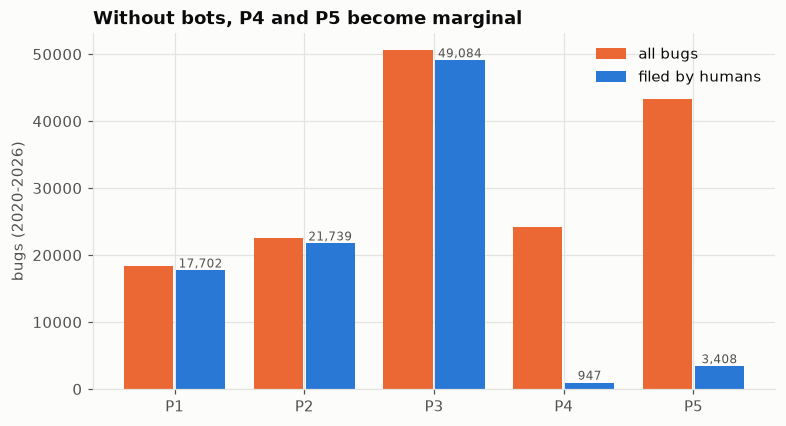

,priority,all_bugs,human,bot_share_%
0,P1,18344,17702,3.5
1,P2,22512,21739,3.4
2,P3,50588,49084,3.0
3,P4,24197,947,96.1
4,P5,43264,3408,92.1


In [7]:
share = sql(f'''
SELECT priority, COUNT(*) AS all_bugs, SUM({human_sql()}) AS human FROM bugs
WHERE priority != '--' GROUP BY priority ORDER BY priority
''')
share["bot_share_%"] = (100 * (1 - share.human / share.all_bugs)).round(1)

fig, ax = plt.subplots()
x = np.arange(len(share))
ax.bar(x - 0.2, share.all_bugs, width=0.38, label="all bugs", color=SERIES[1])
ax.bar(x + 0.2, share.human, width=0.38, label="filed by humans", color=SERIES[0])
ax.set_xticks(x, share.priority)
ax.set_ylabel("bugs (2020-2026)")
ax.set_title("Without bots, P4 and P5 become marginal")
for xi, h in enumerate(share.human):
    ax.text(xi + 0.2, h, f"{h:,}", ha="center", va="bottom", fontsize=8, color="#52514e")
ax.legend()
plt.show()
share

## 3. Target classes

Without bots, P4 has fewer than 1,000 human bugs in six years. P4 and P5 are merged into a **Low** class, giving four ordered levels that each map to a distinct action: current release, next release, backlog, won't fix. The description sample was completed with all human P4/P5 bugs, which were under-represented in the random draw.

In [8]:
from jem_prioriser import dataset

labeled = dataset.load_labeled()
print(f"{len(labeled)} labelled human bugs with a description")
labeled["label"].value_counts().sort_index().to_frame("bugs")

21209 labelled human bugs with a description


,bugs
label,
P1,3371
P2,4060
P3,9423
Low,4355


## 4. Data leakage

The database holds the **current** state of each bug. A field can only be used if it is known **when the bug is filed**, before triage.

In [9]:
raw = sql(f'''
SELECT b.priority, b.severity, b.status, d.n_comments
FROM descriptions d JOIN bugs b ON b.id = d.bug_id
WHERE b.priority != '--' AND {human_sql('b.creator')}
''')
raw["label"] = raw.priority.map(LABEL_OF_PRIORITY)
(pd.crosstab(raw.severity, raw.label, normalize="columns") * 100).round(1)[CLASSES]

label,P1,P2,P3,Low
severity,,,,
--,21.2,11.5,14.2,8.7
N/A,20.0,19.7,19.1,21.7
S1,1.7,0.0,0.0,0.0
S2,14.3,10.0,0.9,0.4
S3,27.3,45.6,47.6,19.2
S4,6.8,6.7,14.2,45.0
blocker,0.1,0.0,0.0,0.0
critical,0.7,0.2,0.0,0.0
major,0.1,0.0,0.0,0.0


In [10]:
(pd.crosstab(raw.status, raw.label, normalize="columns") * 100).round(1)[CLASSES]

label,P1,P2,P3,Low
status,,,,
ASSIGNED,0.9,1.6,1.8,1.0
NEW,2.1,14.2,33.9,39.1
REOPENED,0.0,0.4,1.0,0.9
RESOLVED,69.8,69.0,52.9,48.5
UNCONFIRMED,0.1,1.8,5.8,8.4
VERIFIED,27.0,13.0,4.7,2.1


In [11]:
raw.groupby("label").n_comments.median().to_frame("comments (median)").loc[CLASSES]

,comments (median)
label,
P1,7.0
P2,7.0
P3,5.0
Low,5.0


| Field | Finding | Decision |
|---|---|---|
| `severity` | S4 for 45% of "Low" bugs vs 7% of P1; set by the triager at the same time as the priority | excluded |
| `status`, `resolution` | 27% of P1 are `VERIFIED` vs 2% of "Low": a consequence of the priority | excluded |
| number of comments | higher for P1/P2 because they are worked on first | excluded |
| `keywords` | partly added by triagers (`regression`, `good-first-bug`…) | excluded as a precaution |
| summary, description, product, component, type, OS | filled in when the bug is filed | kept |

Accepted residual risk: a triager may move a bug to another component.

## 5. Temporal drift

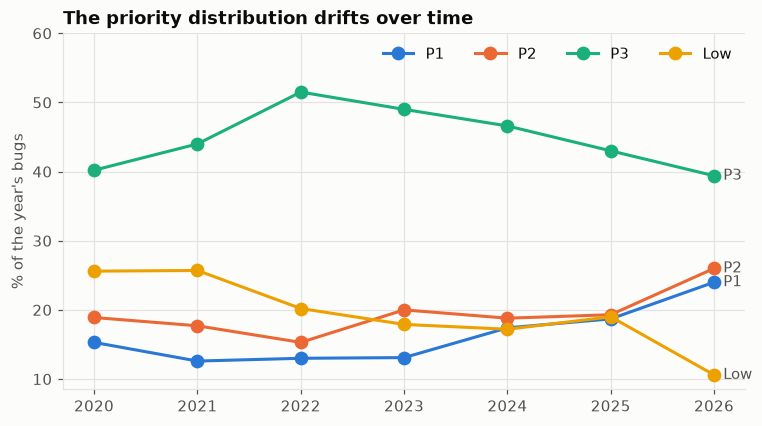

In [12]:
labeled["year"] = labeled.creation_time.dt.year
by_year = (pd.crosstab(labeled.year, labeled.label, normalize="index") * 100).round(1)
fig, ax = plt.subplots()
for c in CLASSES:
    ax.plot(by_year.index, by_year[c], marker="o", label=c, color=CLASS_COLORS[c])
    ax.annotate(c, (by_year.index[-1], by_year[c].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color="#52514e")
ax.set_ylabel("% of the year's bugs")
ax.set_ylim(top=60)
ax.set_title("The priority distribution drifts over time")
ax.legend(ncol=4, loc="upper right")
plt.show()

In 2026, the share of "Low" drops to 11%: recent bugs have not yet been moved to P5, a decision often taken months later. A random split would mix past and future and overestimate performance. Evaluation is therefore done **on the future**:

In [13]:
train, val, test = dataset.temporal_split(labeled)
parts = [("train 2020-2024", train), ("validation 2025", val), ("test 2026", test)]
splits = pd.DataFrame({name: part.label.value_counts(normalize=True).round(3) for name, part in parts}).T[CLASSES]
splits["bugs"] = [len(part) for _, part in parts]
splits

label,P1,P2,P3,Low,bugs
train 2020-2024,0.143,0.182,0.453,0.221,16345
validation 2025,0.187,0.193,0.430,0.190,2649
test 2026,0.240,0.260,0.394,0.106,2215


## 6. Text

In [14]:
labeled["desc_len"] = labeled.description.str.len()
labeled.groupby("label").agg(
    median_length=("desc_len", "median"),
    empty_description_pct=("desc_len", lambda s: round(100 * (s == 0).mean(), 1)),
).loc[CLASSES]

,median_length,empty_description_pct
label,,
P1,408.0,8.1
P2,487.0,7.1
P3,486.0,8.9
Low,556.0,6.8


Descriptions are a few hundred characters long (median), empty in ~8% of cases, and truncated to 4,000 characters (some embed multi-MB logs). Length does not separate the classes: the signal has to come from vocabulary and component.

## Decisions

| Decision | Rationale | Implementation |
|---|---|---|
| Mozilla Bugzilla, since 2020 | open API, volume, real untriaged backlog | `collect.py` |
| Exclude 13 bot accounts | 96% of P4 and 92% of P5 bugs | `cleaning.py` |
| 4 classes: P1, P2, P3, Low | P4 almost unused by humans | `cleaning.py` |
| Exclude severity, status, resolution, keywords, comments | leakage: set during or after triage | `dataset.py` |
| Chronological split | distribution drift; the task is predicting the future | `dataset.temporal_split` |
| Bot bugs kept aside | natural out-of-distribution set for evaluation | `dataset.load_bot_bugs` |

In [15]:
db.close()